In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# Load training and testing datasets
df=pd.read_csv('/content/drive/MyDrive/heart.csv')


# Display the first few rows
print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [ ]:
df.shape
df.info()
df.describe().T
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
#target variable
df.target.value_counts()

,count
target,
1,526
0,499


In [ ]:
print(df.isnull().sum())  # Check missing values in training data


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


<Axes: >

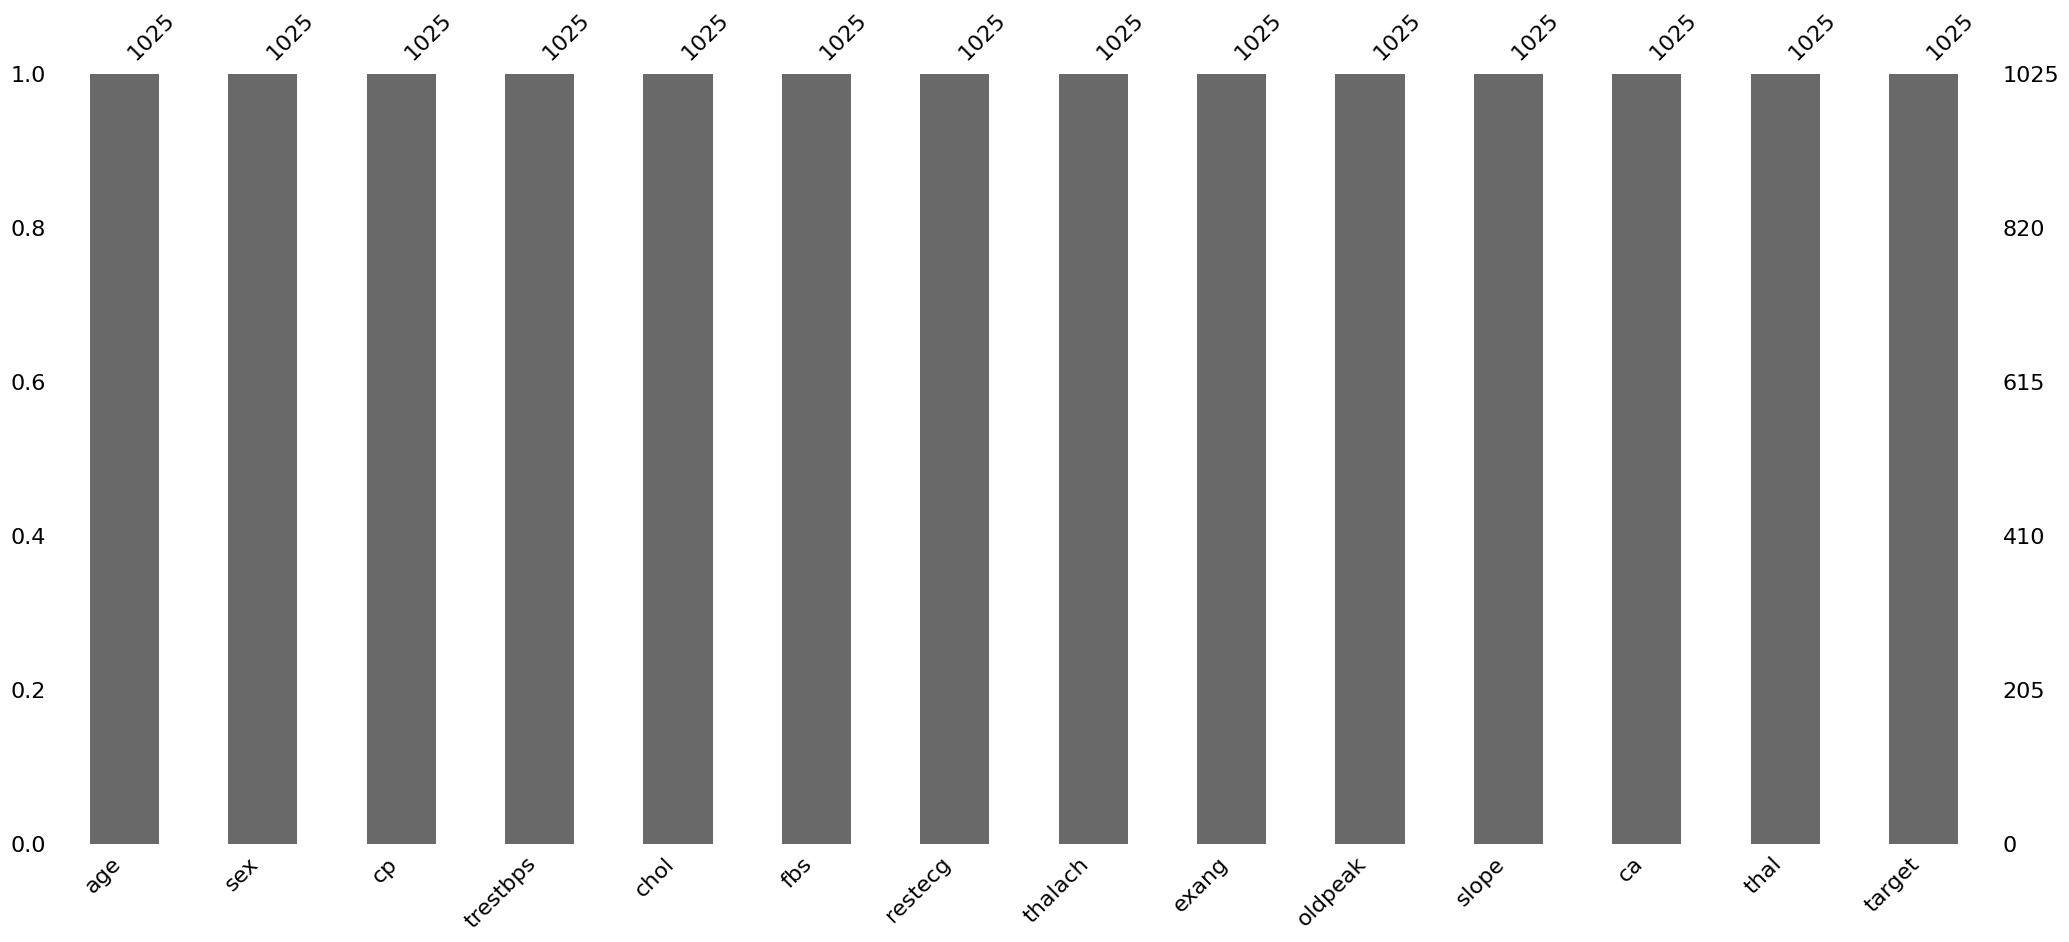

In [ ]:
#visualizing null values
import missingno as msno
msno.bar(df)

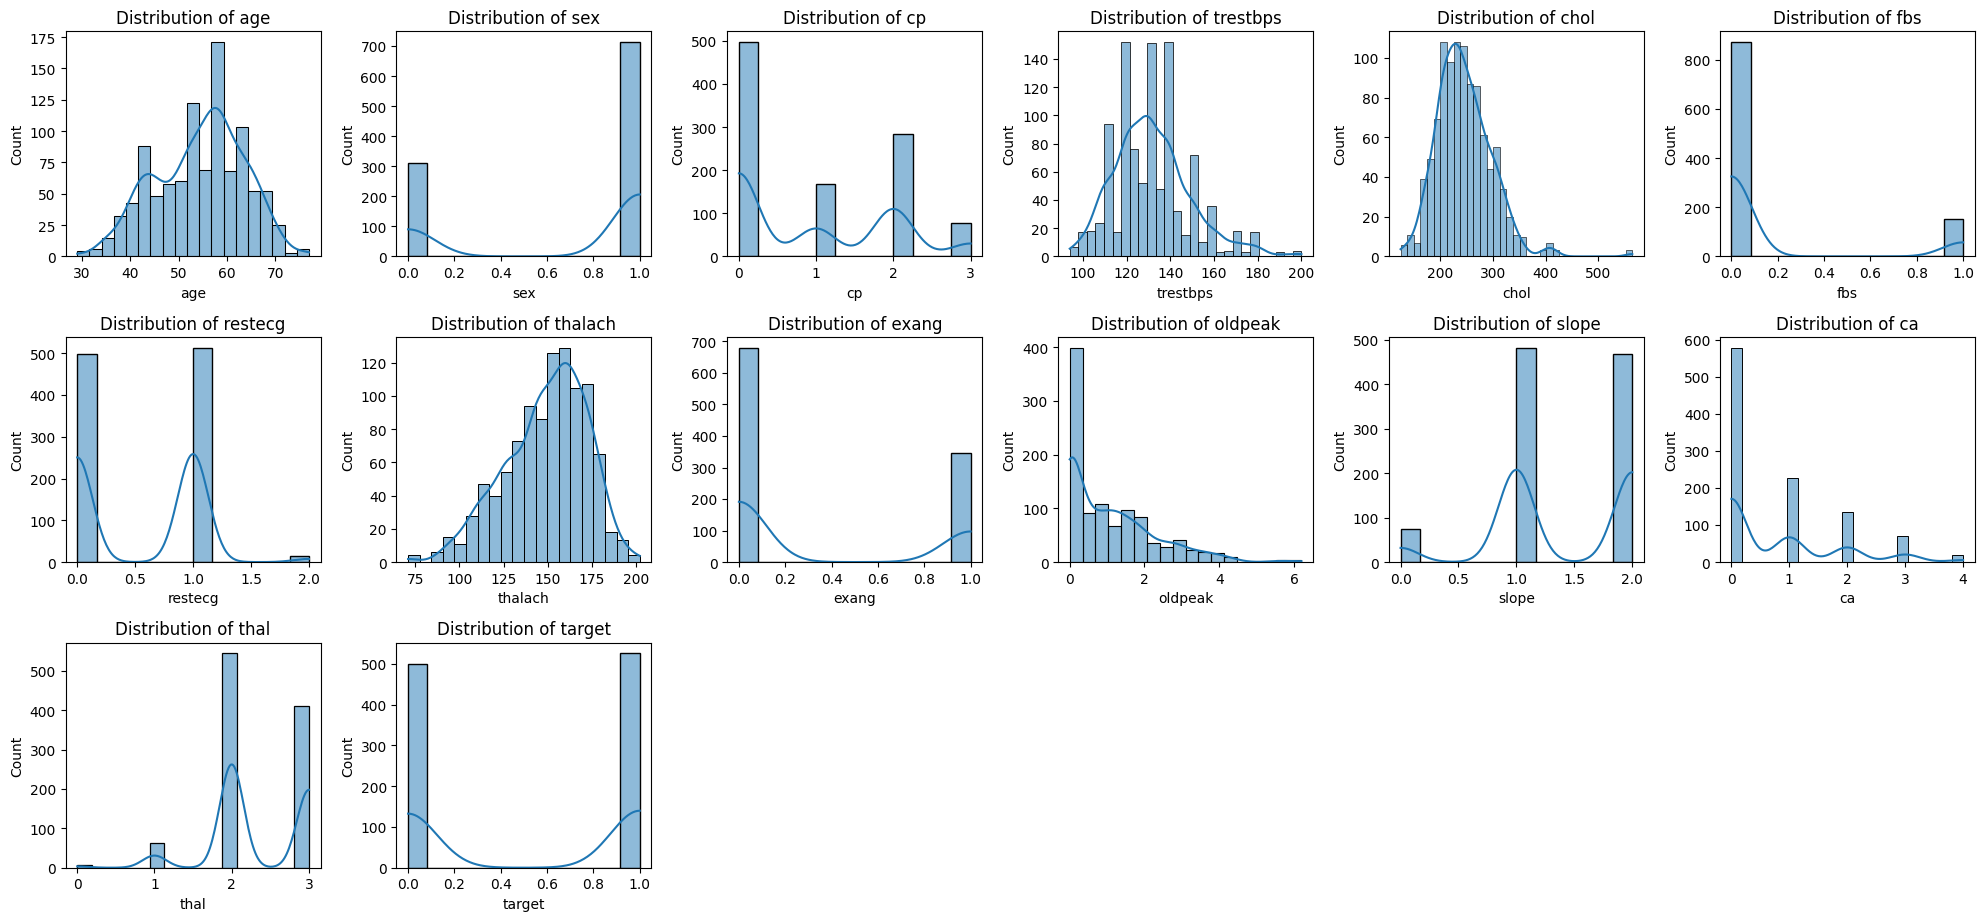

In [ ]:
#histplot
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 15))
plotnumber = 1

for column in df.columns:
    if plotnumber <= 30:
        ax = plt.subplot(5, 6, plotnumber)  # Creates a grid of 5 rows and 6 columns
        sns.histplot(df[column], kde=True)  # Use histplot with kde for density
        plt.xlabel(column)
        plt.title(f'Distribution of {column}')

    plotnumber += 1

plt.tight_layout()
plt.show()

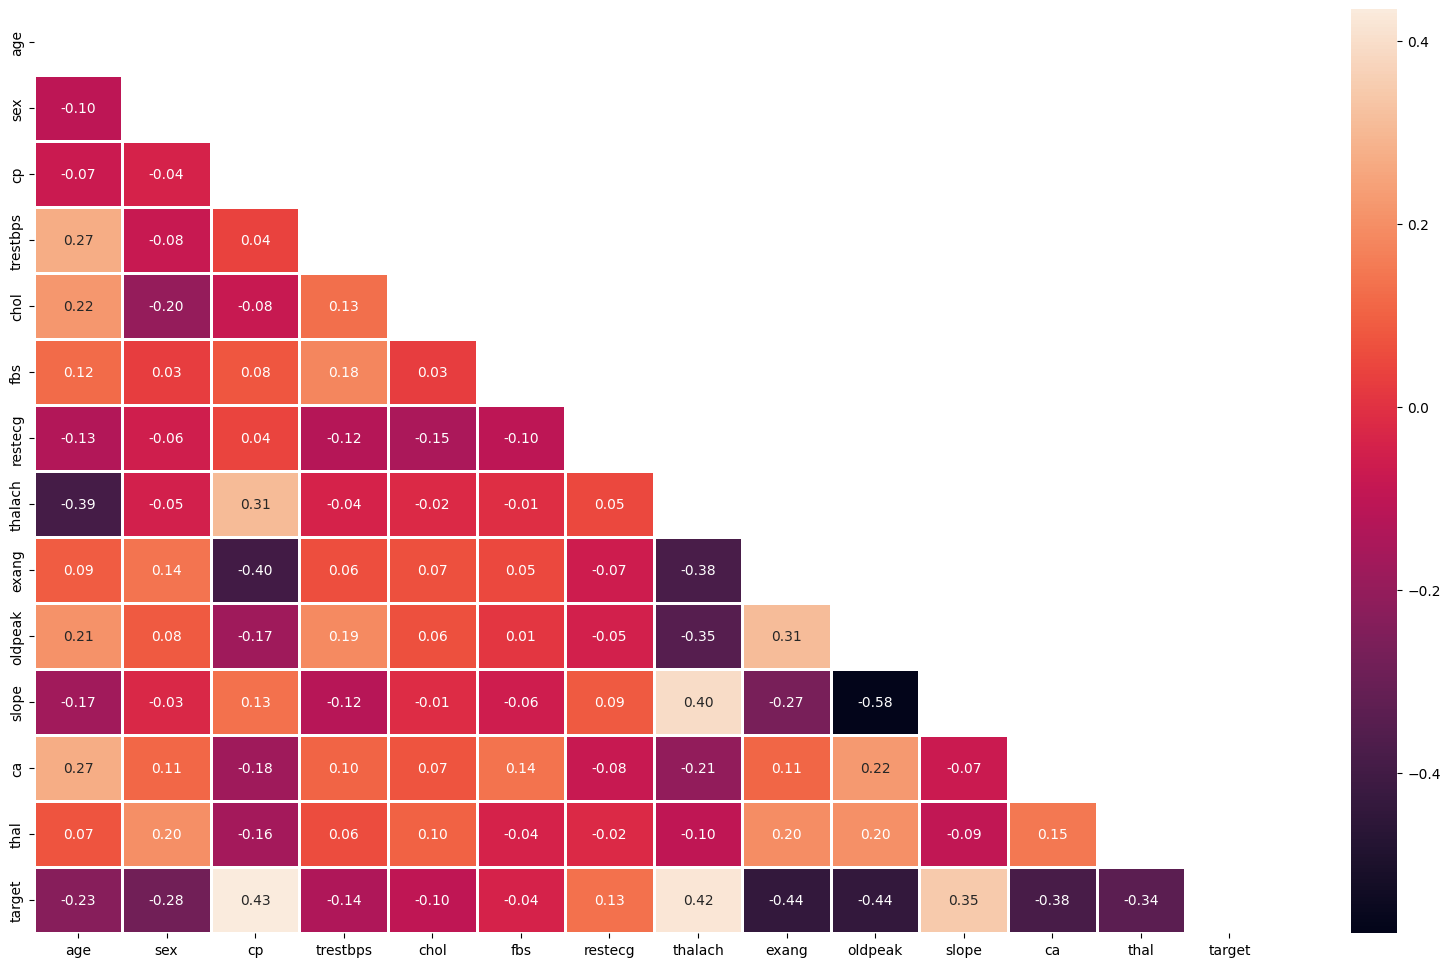

In [ ]:
#heatmap
import numpy as np
plt.figure(figsize = (20, 12))

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype = bool))

sns.heatmap(corr, mask = mask, linewidths = 1, annot = True, fmt = ".2f")
plt.show()

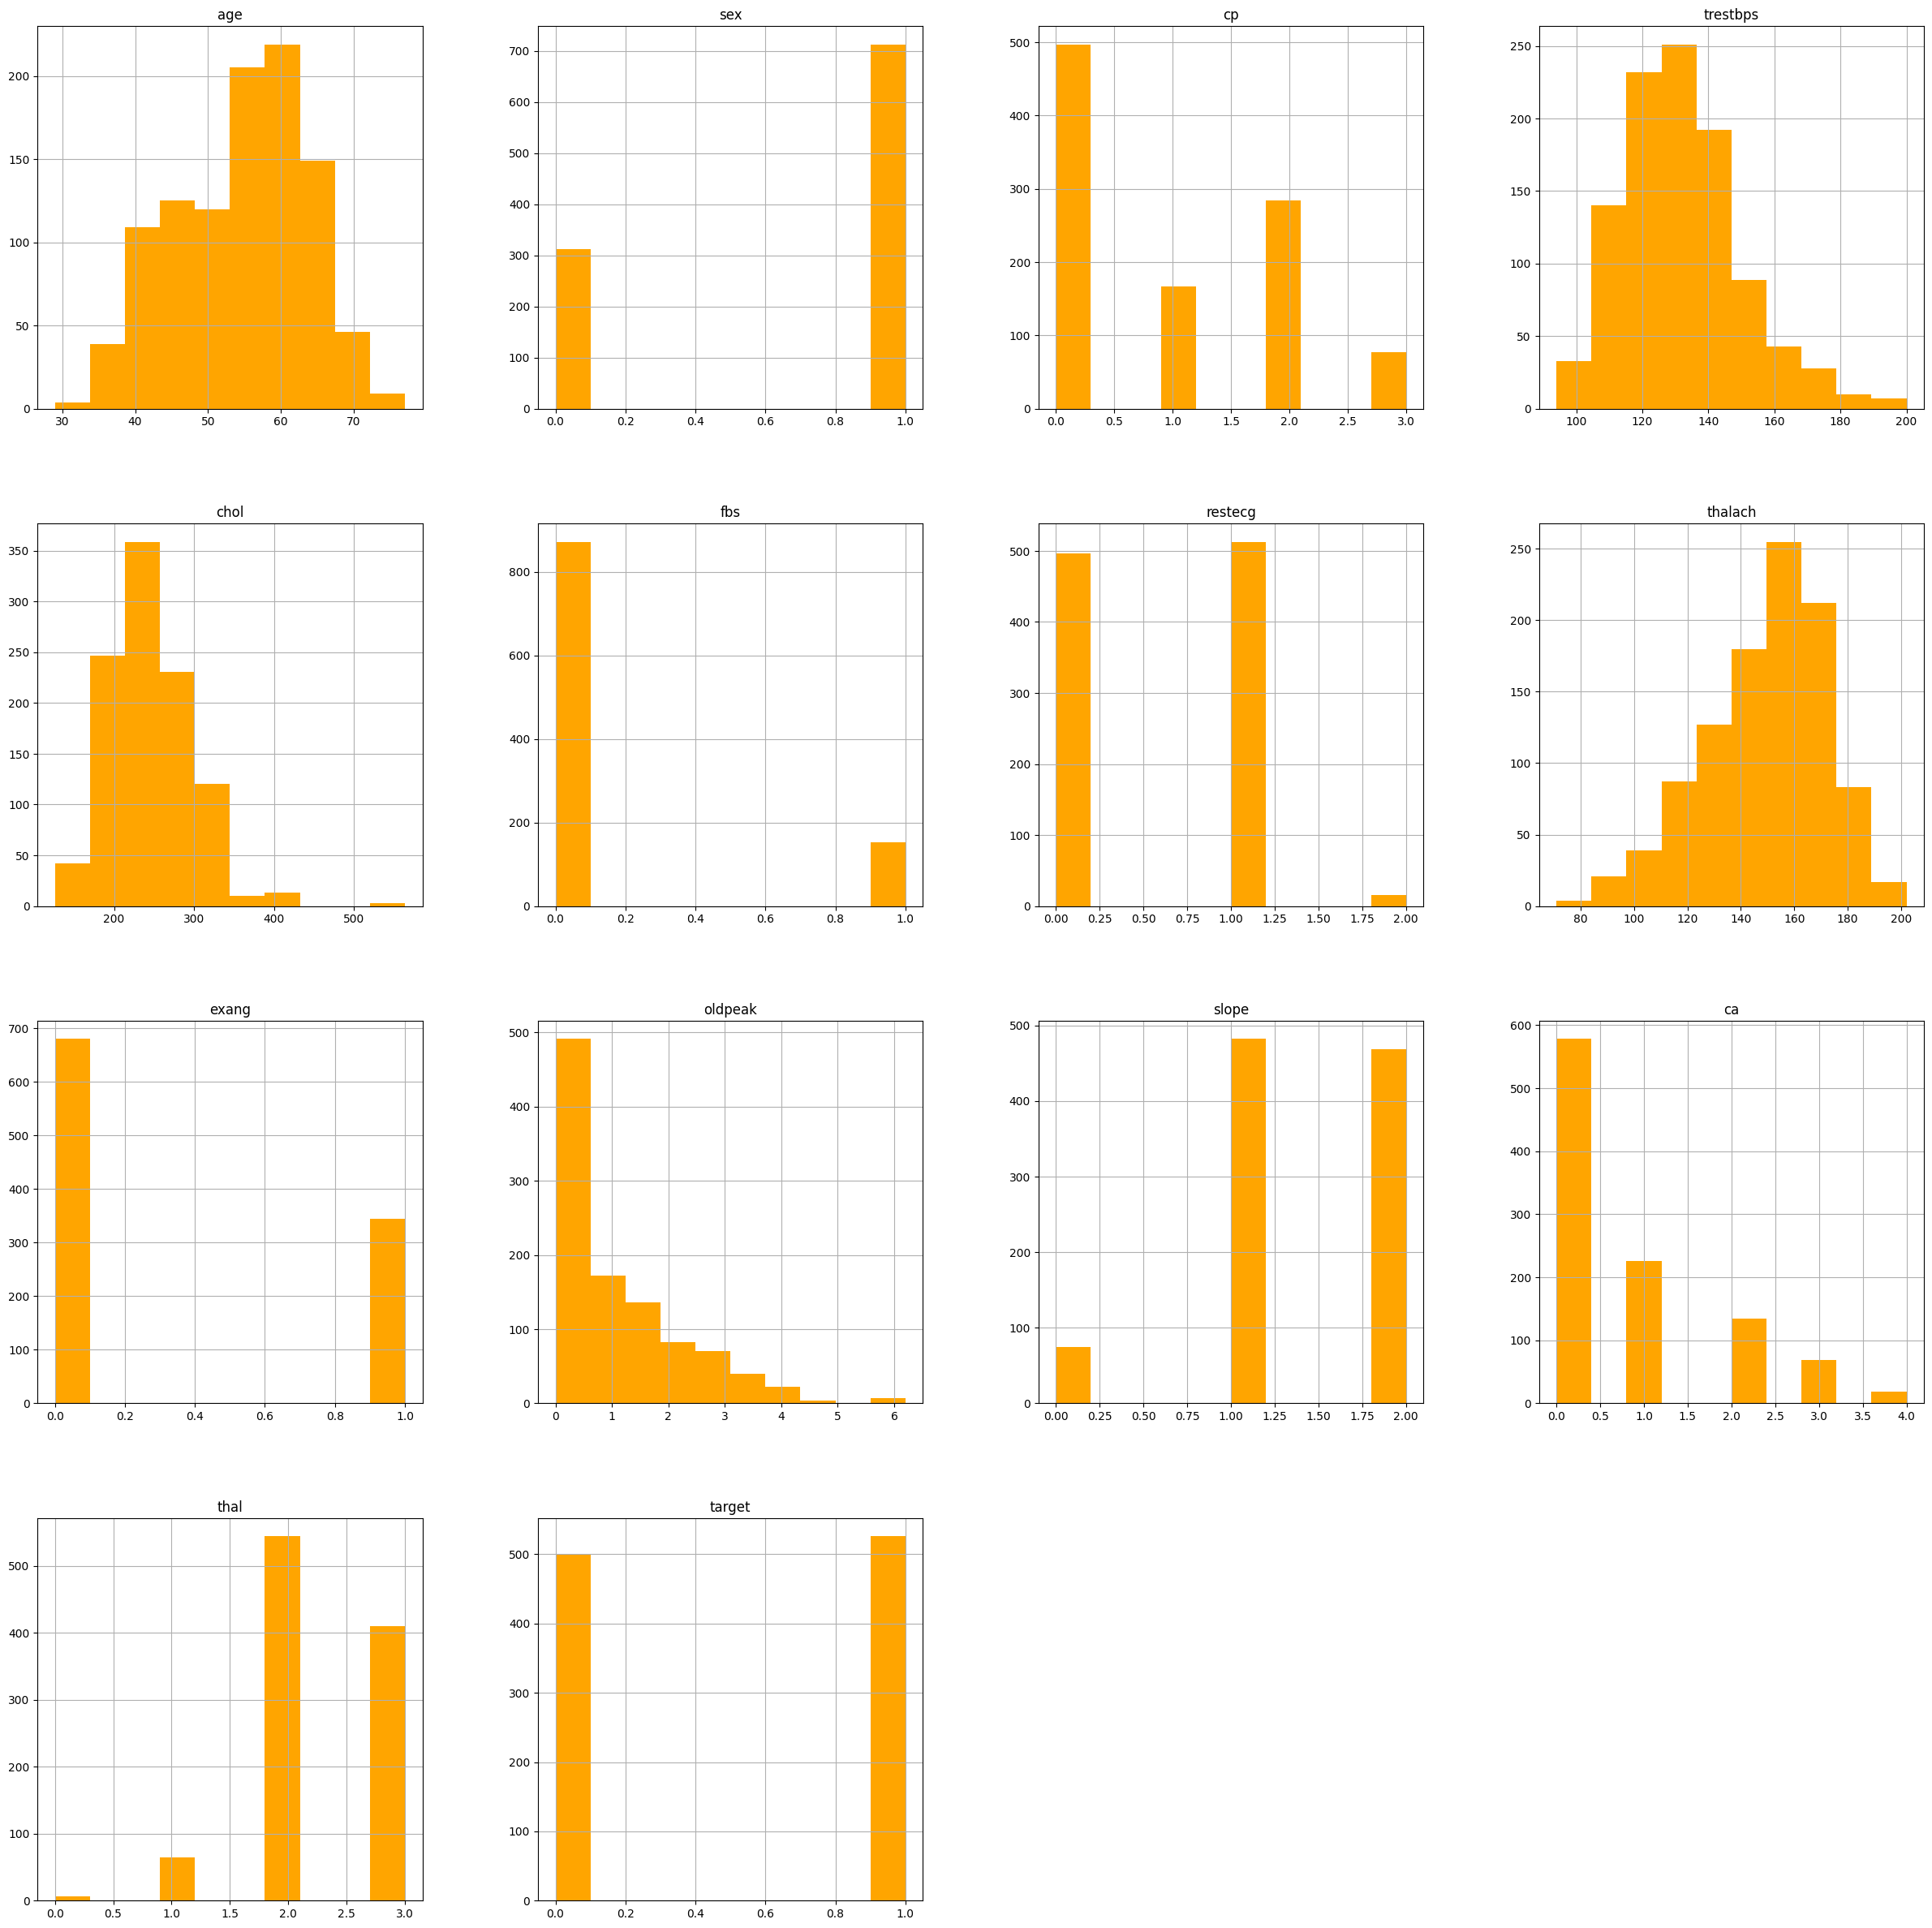

In [ ]:
#plot the histograms for each feature:
df.hist(figsize = (30,30), color = 'orange')
plt.show()

In [ ]:
# removing highly correlated features

corr_matrix = df.corr().abs()

mask = np.triu(np.ones_like(corr_matrix, dtype = bool))
tri_df = corr_matrix.mask(mask)

to_drop = [x for x in tri_df.columns if any(tri_df[x] > 0.92)]

df = df.drop(to_drop, axis = 1)

print(f"The reduced dataframe has {df.shape[1]} columns.")

The reduced dataframe has 14 columns.


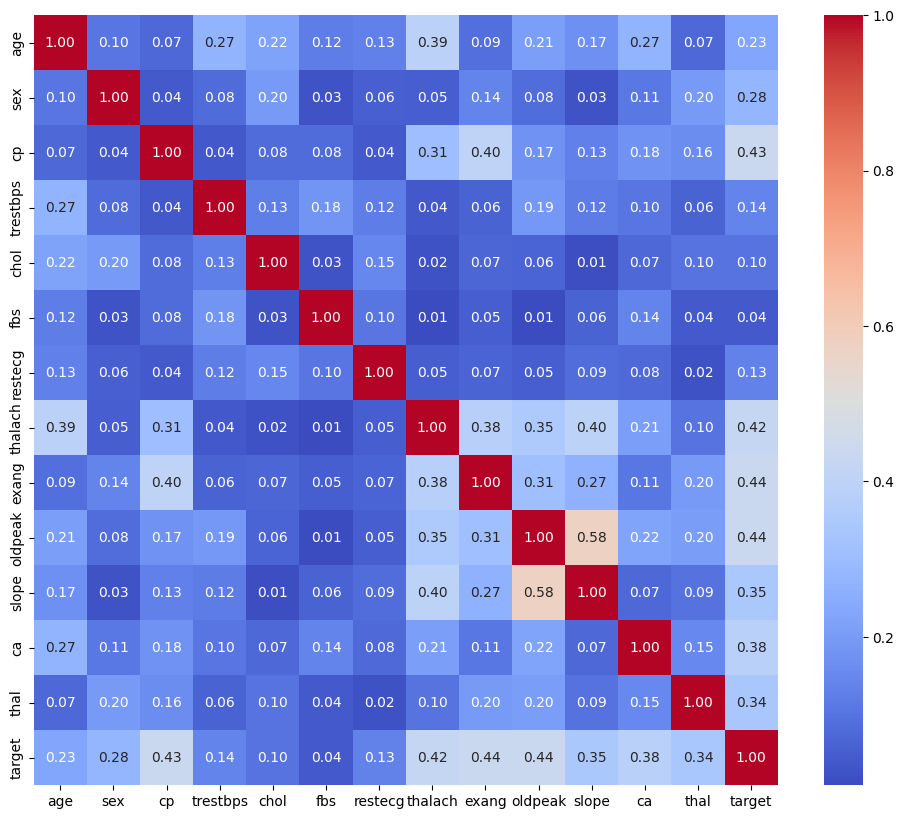

In [ ]:
# Recalculate the correlation matrix
new_corr_matrix = df.corr().abs()
plt.figure(figsize=(12, 10))
sns.heatmap(new_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [ ]:
# creating features and label

X = df.drop('target', axis = 1)
y = df['target']

In [ ]:
# Splitting the data into training set and testset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state = 0)
print("Size of training set:", X_train.shape)
print("Size of test set:", X_test.shape)

Size of training set: (717, 13)
Size of test set: (308, 13)


In [ ]:
x_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

Imbalanced Dataset Oversampling using SMOTE

In [ ]:
import imblearn
from imblearn.over_sampling import SMOTE
from collections import Counter

counter = Counter(y_train)
counter

Counter({1: 363, 0: 354})

In [ ]:
upsample = SMOTE()
X_train, y_train = upsample.fit_resample(X_train, y_train)
counter = Counter(y_train)
print(counter)

Counter({1: 363, 0: 363})


In [ ]:
print(f"Train Data: {X_train.shape}, {y_train.shape}")
print(f"Test Data: {X_test.shape}, {y_test.shape}")

Train Data: (726, 13), (726,)
Test Data: (308, 13), (308,)


In [ ]:
# scaling data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Visualization and Feature Extraction


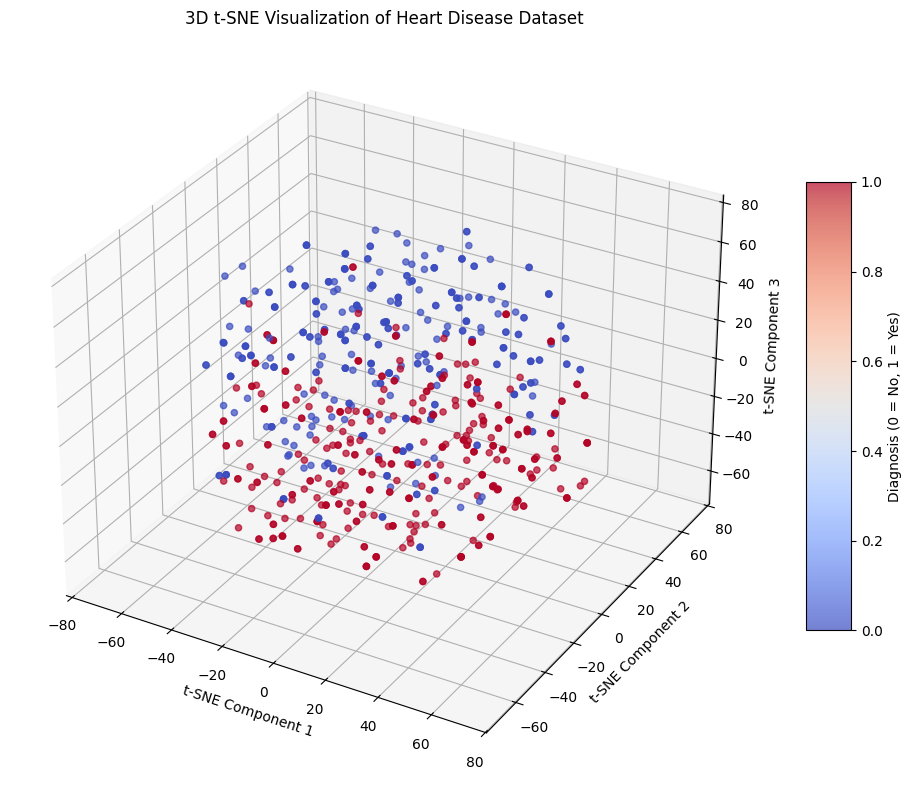

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # for 3D plotting
from sklearn.manifold import TSNE

# Apply t-SNE with 3 components
tsne = TSNE(n_components=3, perplexity=60, n_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_train)

# #D Visualization
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], X_tsne[:, 2],
                     c=y_train, cmap='coolwarm', alpha=0.7)

# Labels and title
ax.set_title("3D t-SNE Visualization of Heart Disease Dataset")
ax.set_xlabel("t-SNE Component 1")
ax.set_ylabel("t-SNE Component 2")
ax.set_zlabel("t-SNE Component 3")

# Color legend
legend = fig.colorbar(scatter, ax=ax, shrink=0.6, aspect=10)
legend.set_label("Diagnosis (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

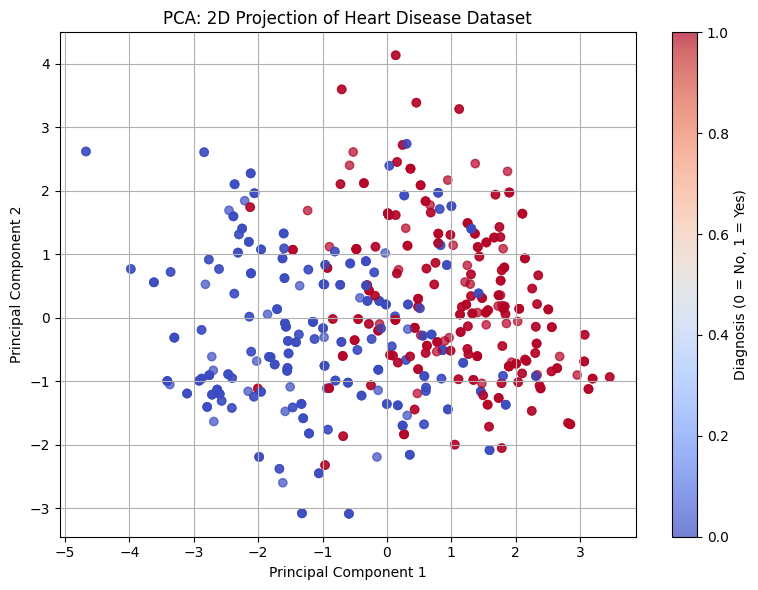

In [ ]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: 2D Projection of Heart Disease Dataset')
plt.colorbar(label='Diagnosis (0 = No, 1 = Yes)')
plt.grid(True)
plt.tight_layout()
plt.show()

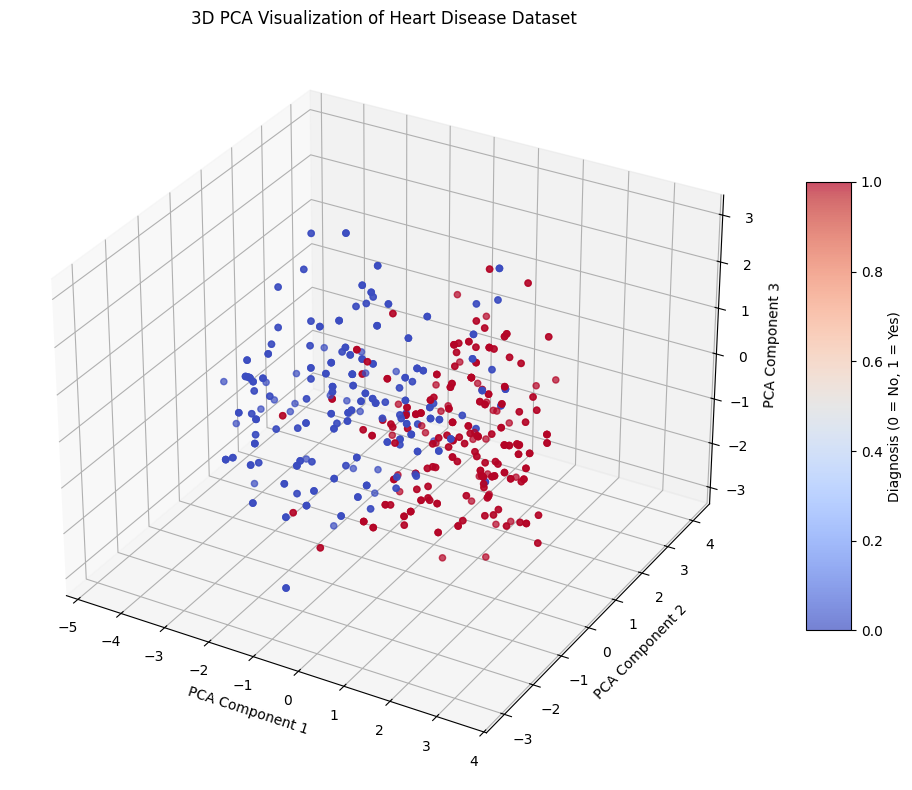

In [ ]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

pca = PCA(n_components=3)
X_pca_3d = pca.fit_transform(X_train)

# Plotting 3D PCA
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
    c=y_train, cmap='coolwarm', alpha=0.7
)

ax.set_title("3D PCA Visualization of Heart Disease Dataset")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_zlabel("PCA Component 3")

cbar = fig.colorbar(scatter, ax=ax, shrink=0.6, aspect=10)
cbar.set_label("Diagnosis (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()

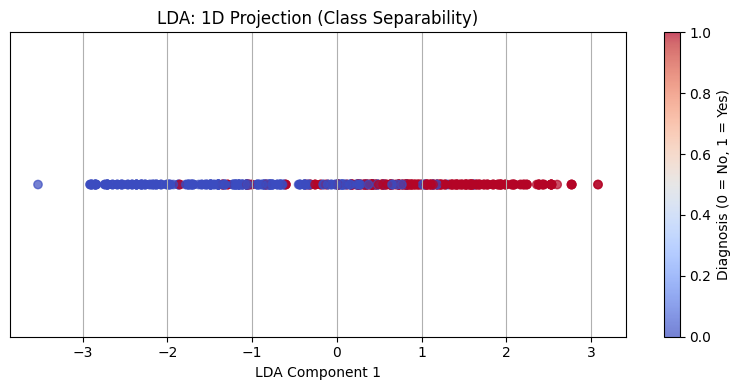

In [ ]:
# Apply LDA
lda = LDA(n_components=1)
X_lda = lda.fit_transform(X_train, y_train)

# Plot
plt.figure(figsize=(8, 4))
plt.scatter(X_lda[:, 0], [0]*len(X_lda), c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel('LDA Component 1')
plt.title('LDA: 1D Projection (Class Separability)')
plt.yticks([])
plt.colorbar(label='Diagnosis (0 = No, 1 = Yes)')
plt.grid(True)
plt.tight_layout()
plt.show()

##lda and pca on GBC

In [ ]:
# Step 1: Apply LDA (only 1 component since it's binary classification)
lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

# Step 2: Classification using GBC

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
clf_lda_gbc = GradientBoostingClassifier()
clf_lda_gbc.fit(X_train_lda, y_train)

# Step 3: Evaluation
y_pred_lda_gbc = clf_lda_gbc.predict(X_test_lda)
print("LDA + GBC Accuracy:", accuracy_score(y_test, y_pred_lda_gbc))
print(classification_report(y_test, y_pred_lda_gbc))

# confusion matrix

print(confusion_matrix(y_test, y_pred_lda_gbc))

LDA + GBC Accuracy: 0.9448051948051948
              precision    recall  f1-score   support

           0       0.94      0.94      0.94       145
           1       0.95      0.95      0.95       163

    accuracy                           0.94       308
   macro avg       0.94      0.94      0.94       308
weighted avg       0.94      0.94      0.94       308

[[136   9]
 [  8 155]]


In [ ]:

from sklearn.metrics import accuracy_score, classification_report,  confusion_matrix

# Apply PCA
pca = PCA(n_components=7)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Classification using Gradient Boosting Classifier
clf_pca_gbc = GradientBoostingClassifier(random_state=42)
clf_pca_gbc.fit(X_train_pca, y_train)

# Evaluation
y_pred_pca_gbc = clf_pca_gbc.predict(X_test_pca)
print("PCA + GBC Accuracy:", accuracy_score(y_test, y_pred_pca_gbc))
print(classification_report(y_test, y_pred_pca_gbc))

# confusion matrix

print(confusion_matrix(y_test, y_pred_pca_gbc))

PCA + GBC Accuracy: 0.987012987012987
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       145
           1       1.00      0.98      0.99       163

    accuracy                           0.99       308
   macro avg       0.99      0.99      0.99       308
weighted avg       0.99      0.99      0.99       308

[[145   0]
 [  4 159]]


##pca on catboost

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 5.7 MB/s eta 0:00:00



Training CatBoost Classifier with PCA-transformed data
0:	learn: 0.6588843	total: 49.6ms	remaining: 4.91s
2:	learn: 0.6015629	total: 53.4ms	remaining: 1.73s
4:	learn: 0.5549681	total: 57.1ms	remaining: 1.08s
6:	learn: 0.5136725	total: 60.9ms	remaining: 809ms
8:	learn: 0.4830832	total: 64.7ms	remaining: 654ms
10:	learn: 0.4525217	total: 68.4ms	remaining: 554ms
12:	learn: 0.4259448	total: 72.3ms	remaining: 484ms
14:	learn: 0.4066559	total: 76.2ms	remaining: 432ms
16:	learn: 0.3858789	total: 80.1ms	remaining: 391ms
18:	learn: 0.3690907	total: 84.2ms	remaining: 359ms
20:	learn: 0.3550954	total: 88ms	remaining: 331ms
22:	learn: 0.3421945	total: 91.7ms	remaining: 307ms
24:	learn: 0.3312563	total: 95.5ms	remaining: 286ms
26:	learn: 0.3219451	total: 99.2ms	remaining: 268ms
28:	learn: 0.3101657	total: 103ms	remaining: 252ms
30:	learn: 0.3005642	total: 107ms	remaining: 237ms
32:	learn: 0.2913194	total: 111ms	remaining: 224ms
34:	learn: 0.2826281	total: 114ms	remaining: 212ms
36:	learn: 0.273901

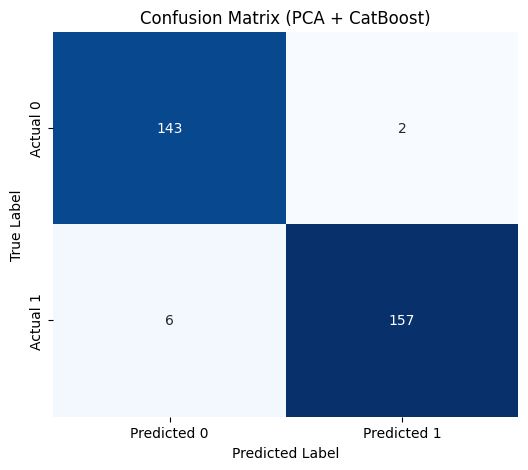

In [ ]:

from catboost import CatBoostClassifier # Import CatBoostClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
# -- Train CatBoost Classifier on PCA-transformed data ---

model_pca_catboost = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    verbose=2,
    random_seed=42, # For reproducibility

)

print("\nTraining CatBoost Classifier with PCA-transformed data")
model_pca_catboost.fit(X_train_pca, y_train)

# --- 6. Make Predictions and Evaluate the Model ---
y_pred_pca_catboost = model_pca_catboost.predict(X_test_pca)

print("\n--- PCA + CatBoost Evaluation ---")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_pca_catboost):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_pca_catboost))

cm_pca_catboost = confusion_matrix(y_test, y_pred_pca_catboost)
print("\nConfusion Matrix:")
print(cm_pca_catboost)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_pca_catboost, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix (PCA + CatBoost)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()



##SVC

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.svm import SVC

# Create and train the SVM model
model = SVC(kernel="rbf", C=1.0, gamma="scale")
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.9545

Confusion Matrix:
 [[138   7]
 [  7 156]]

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.95      0.95       145
           1       0.96      0.96      0.96       163

    accuracy                           0.95       308
   macro avg       0.95      0.95      0.95       308
weighted avg       0.95      0.95      0.95       308



##Gradient boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create and train the model
model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.9708

Confusion Matrix:
 [[140   5]
 [  4 159]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97       145
           1       0.97      0.98      0.97       163

    accuracy                           0.97       308
   macro avg       0.97      0.97      0.97       308
weighted avg       0.97      0.97      0.97       308



##decision tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the model
model = DecisionTreeClassifier(criterion="gini", max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Model Accuracy: 0.9123

Confusion Matrix:
 [[122  23]
 [  4 159]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.84      0.90       145
           1       0.87      0.98      0.92       163

    accuracy                           0.91       308
   macro avg       0.92      0.91      0.91       308
weighted avg       0.92      0.91      0.91       308



## XGBoost (Extreme Gradient Boosting)

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split

model = xgb.XGBClassifier()  # or XGBRegressor for regression tasks


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to try
param_grid = {
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'n_estimators': [100, 200, 300],
    'subsample': [0.7, 0.8, 1.0]
}

model = xgb.XGBClassifier()

# Grid Search
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='accuracy',  # Or 'neg_mean_squared_error' for regression
    cv=5,                # 5-fold cross-validation
    verbose=1,           # Print progress
    n_jobs=-1            # Use all CPU cores
)

# Fit grid search
grid_search.fit(X_train, y_train)

# Best parameters
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Score:", grid_search.best_score_)



Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best Hyperparameters: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0}
Best Score: 0.9820784128483704


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load some sample data
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create the model
model = xgb.XGBClassifier()

# Define param_distributions
param_distributions = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7, 9],
    'n_estimators': [100, 200, 300, 400],
    'subsample': [0.6, 0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'gamma': [0, 1, 5],
    'reg_alpha': [0, 0.5, 1],
    'reg_lambda': [0, 0.5, 1]
}

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,  # <-- Now correctly using param_distributions
    n_iter=20,    # Try 20 random combinations
    scoring='accuracy',
    cv=5,         # 5-fold cross-validation
    verbose=1,
    n_jobs=-1,    # Use all CPU cores
    random_state=42
)

# Fit RandomizedSearchCV
random_search.fit(X_train, y_train)

# Best parameters and score
print("Best Hyperparameters:", random_search.best_params_)
print("Best Cross-validation Score:", random_search.best_score_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Hyperparameters: {'subsample': 0.8, 'reg_lambda': 0, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}
Best Cross-validation Score: 0.9736263736263737


In [ ]:
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

from sklearn.metrics import accuracy_score
print("Test Accuracy:", accuracy_score(y_test, y_pred))


Test Accuracy: 0.9736842105263158


In [ ]:
from xgboost import XGBClassifier

# Train the model
model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.956140350877193
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.93      0.94        43
           1       0.96      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
from sklearn.metrics import classification_report, f1_score, precision_score

# Get the best model after tuning
best_model = random_search.best_estimator_

# Predict on test set
y_pred = best_model.predict(X_test)

# Show full classification report
print(classification_report(y_test, y_pred))

# OR: Print just F1 and precision
print("F1 Score:", f1_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

F1 Score: 0.9790209790209791
Precision: 0.9722222222222222


In [ ]:
from sklearn.metrics import precision_score, f1_score
precision = precision_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("F1 Score:", f1)

Precision: 0.9722222222222222
F1 Score: 0.9790209790209791


##Naïve Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Train the model
model = GaussianNB()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9736842105263158
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96        43
           1       0.96      1.00      0.98        71

    accuracy                           0.97       114
   macro avg       0.98      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



##LightGBM

In [ ]:
from lightgbm import LGBMClassifier

model = LGBMClassifier(n_estimators=100, learning_rate=0.1, max_depth=3)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000388 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4548
[LightGBM] [Info] Number of data points in the train set: 455, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.628571 -> initscore=0.526093
[LightGBM] [Info] Start training from score 0.526093
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
